In [48]:
import torch
print(torch.cuda.is_available())

True


In [49]:
pip install notebook ipykernel jupyter

Note: you may need to restart the kernel to use updated packages.


In [50]:
import torch

print(torch.__version__)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

2.6.0+cu124
True
NVIDIA GeForce GTX 1650


In [51]:
pip install timm tqdm matplotlib scikit-learn pillow opencv-python

Note: you may need to restart the kernel to use updated packages.


In [52]:
import torch
import torchvision
import torchvision.transforms as transforms

import torch.nn as nn
import torch.optim as optim

import numpy as np
import matplotlib.pyplot as plt

from torchvision import models
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

print("PyTorch :", torch.__version__)
print("CUDA :", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device :", device)

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

PyTorch : 2.6.0+cu124
CUDA : True
Device : cuda
NVIDIA GeForce GTX 1650


In [53]:
train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(224, padding=16),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [54]:
train_dataset = torchvision.datasets.CIFAR100(
    root="./datasets",
    train=True,
    download=False,
    transform=train_transform
)

test_dataset = torchvision.datasets.CIFAR100(
    root="./datasets",
    train=False,
    download=False,
    transform=test_transform
)


In [55]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [56]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Device: cuda
GPU: NVIDIA GeForce GTX 1650


In [57]:
from torchvision import models

model = models.resnet50(
    weights=models.ResNet50_Weights.IMAGENET1K_V2
)

model = model.to(device)

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [58]:
for param in model.parameters():
    param.requires_grad = False

In [59]:
for param in model.layer3.parameters():
    param.requires_grad = True
for param in model.layer4.parameters():
    param.requires_grad = True    

In [60]:
import torch
import torchvision
import torchvision.transforms as transforms

import torch.nn as nn
import torch.optim as optim

import numpy as np
import matplotlib.pyplot as plt

from torchvision import models
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

In [61]:
model.fc = nn.Linear(
    model.fc.in_features,
    100
)

model = model.to(device)

In [62]:
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())

print(f"Trainable Parameters : {trainable:,}")
print(f"Total Parameters     : {total:,}")


Trainable Parameters : 22,268,004
Total Parameters     : 23,712,932


In [63]:
criterion = nn.CrossEntropyLoss()

In [64]:
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=3e-5,
    weight_decay=1e-4
)

In [65]:
scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=5,
    gamma=0.1
)

In [66]:
print(model)

print("\nDevice :", device)

print("\nOptimizer :", optimizer)

print("\nLoss :", criterion)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [67]:
def train(model, loader, optimizer, criterion):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in tqdm(loader):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = outputs.max(1)

        total += labels.size(0)

        correct += predicted.eq(labels).sum().item()

    return running_loss / len(loader), 100 * correct / total

In [68]:
def test(model, loader, criterion):

    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in tqdm(loader):

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = outputs.max(1)

            total += labels.size(0)

            correct += predicted.eq(labels).sum().item()

    return running_loss / len(loader), 100 * correct / total

In [69]:
epochs = 25

train_losses = []
test_losses = []

train_accs = []
test_accs = []

best_acc = 0

best_epoch = 0

best_train_loss = 0
best_test_loss = 0

best_train_acc = 0
best_test_acc = 0

for epoch in range(epochs):

    print(f"\nEpoch {epoch+1}/{epochs}")

    train_loss, train_acc = train(
        model,
        train_loader,
        optimizer,
        criterion
    )

    test_loss, test_acc = test(
        model,
        test_loader,
        criterion
    )
    scheduler.step()
    print(f"Learning Rate : {scheduler.get_last_lr()[0]:.8f}")
    train_losses.append(train_loss)
    test_losses.append(test_loss)

    train_accs.append(train_acc)
    test_accs.append(test_acc)

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Train Accuracy : {train_acc:.2f}%")

    print(f"Test Loss : {test_loss:.4f}")
    print(f"Test Accuracy : {test_acc:.2f}%")

    if test_acc > best_acc:

        best_acc = test_acc
        best_epoch = epoch + 1

        best_train_loss = train_loss
        best_test_loss = test_loss

        best_train_acc = train_acc
        best_test_acc = test_acc

        torch.save(
        model.state_dict(),
        "./models/best_resnet50-CIFAR100.pth"
       )
        print("Best Model Saved")


Epoch 1/25


  0%|          | 0/1563 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

Learning Rate : 0.00003000
Train Loss : 2.0867
Train Accuracy : 50.95%
Test Loss : 0.8874
Test Accuracy : 73.98%
Best Model Saved

Epoch 2/25


  0%|          | 0/1563 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

... (66 outputs left out)

Learning Rate : 0.00000000
Train Loss : 0.2120
Train Accuracy : 93.85%
Test Loss : 0.5731
Test Accuracy : 83.92%

Epoch 25/25


  0%|          | 0/1563 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

Learning Rate : 0.00000000
Train Loss : 0.2142
Train Accuracy : 93.68%
Test Loss : 0.5700
Test Accuracy : 83.73%


In [70]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [71]:
import torch
import torchvision
import torchvision.transforms as transforms

import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from torchvision import models
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [72]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device :", device)

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

Device : cuda
GPU : NVIDIA GeForce GTX 1650


In [73]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [74]:
test_dataset = torchvision.datasets.CIFAR100(
    root="./datasets",
    train=False,
    download=False,
    transform=transform
)

In [75]:
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

In [76]:
classes =train_dataset.classes

In [77]:
loaded_model = models.resnet50(weights=None)

loaded_model.fc = nn.Linear(
    loaded_model.fc.in_features,
    100
)

loaded_model.load_state_dict(
    torch.load(
        "./models/best_resnet50-CIFAR100.pth",
        map_location=device
    )
)

loaded_model = loaded_model.to(device)

loaded_model.eval()

print("Best Model Loaded Successfully!")

Best Model Loaded Successfully!


In [78]:
all_preds = []
all_labels = []

loaded_model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = loaded_model(images)

        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("Predictions Generated Successfully!")

Predictions Generated Successfully!


In [79]:
accuracy = accuracy_score(
    all_labels,
    all_preds
)

precision = precision_score(
    all_labels,
    all_preds,
    average="weighted"
)

recall = recall_score(
    all_labels,
    all_preds,
    average="weighted"
)

f1 = f1_score(
    all_labels,
    all_preds,
    average="weighted"
)

print("=" * 50)
print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1 Score  : {f1*100:.2f}%")

print("=" * 50)

Accuracy  : 84.14%
Precision : 84.31%
Recall    : 84.14%
F1 Score  : 84.13%


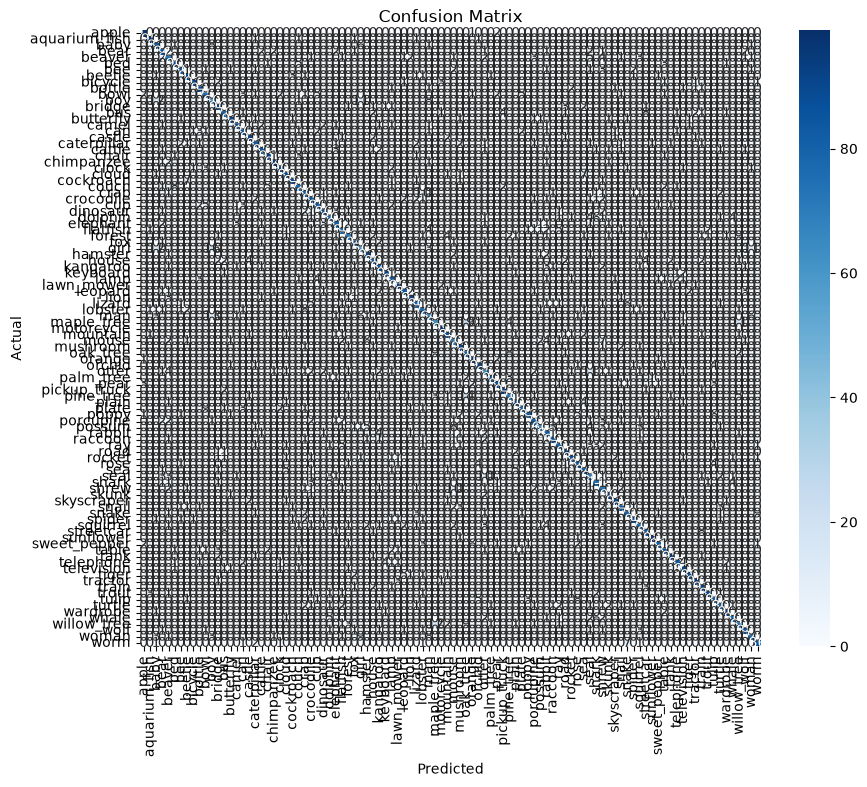

In [80]:
cm = confusion_matrix(
    all_labels,
    all_preds
)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [81]:
print(classification_report(
    all_labels,
    all_preds,
    target_names=classes
))

               precision    recall  f1-score   support

        apple       0.92      0.97      0.94       100
aquarium_fish       0.94      0.95      0.95       100
         baby       0.70      0.83      0.76       100
         bear       0.80      0.84      0.82       100
       beaver       0.70      0.72      0.71       100
          bed       0.87      0.90      0.89       100
          bee       0.91      0.86      0.88       100
       beetle       0.86      0.90      0.88       100
      bicycle       0.97      0.91      0.94       100
       bottle       0.88      0.92      0.90       100
         bowl       0.78      0.75      0.77       100
          boy       0.59      0.60      0.60       100
       bridge       0.85      0.90      0.87       100
          bus       0.83      0.78      0.80       100
    butterfly       0.94      0.91      0.92       100
        camel       0.92      0.88      0.90       100
          can       0.85      0.86      0.86       100
       ca

In [82]:
images, labels = next(iter(test_loader))

images_gpu = images.to(device)

with torch.no_grad():
    outputs = loaded_model(images_gpu)
    _, predicted = torch.max(outputs, 1)

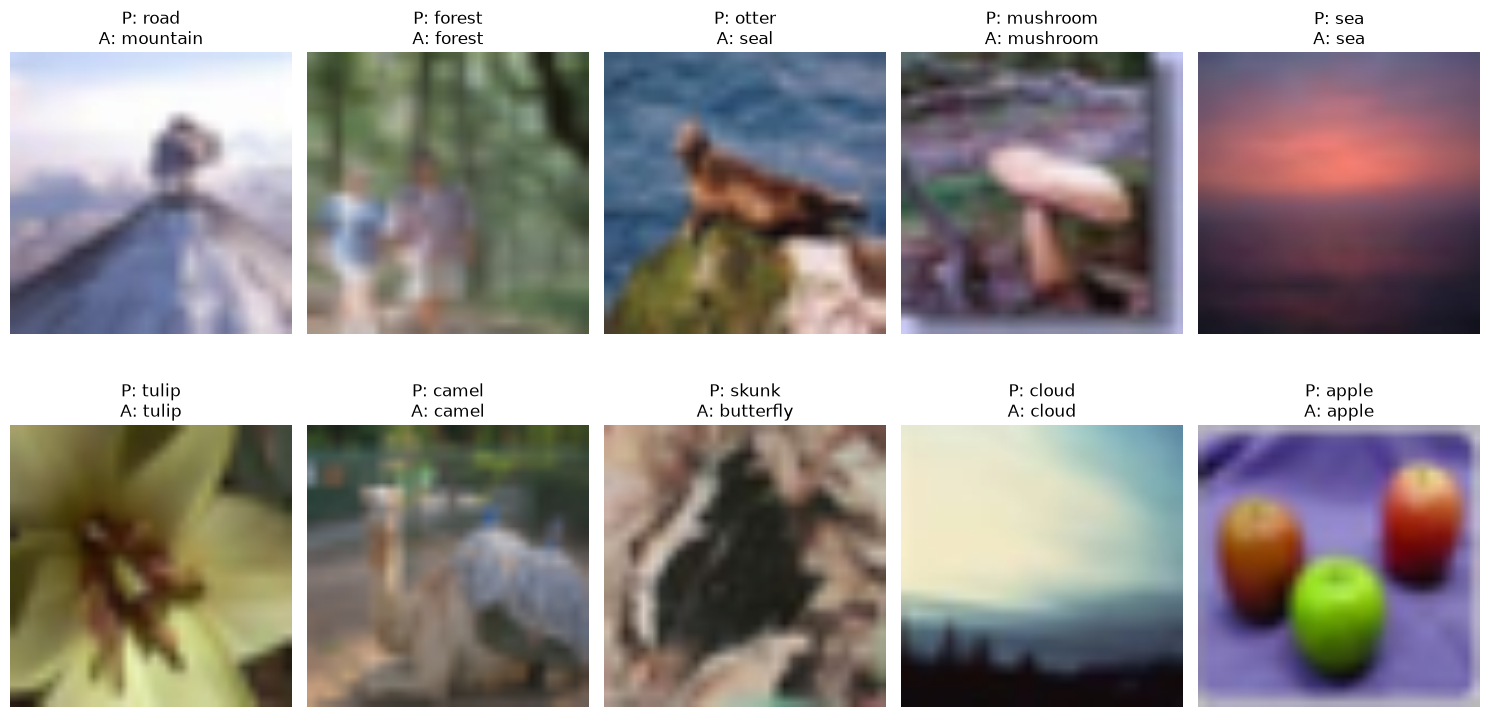

In [83]:
plt.figure(figsize=(15,8))

for i in range(10):

    plt.subplot(2,5,i+1)

    img = images[i].permute(1,2,0).numpy()

    img = img * np.array([0.229,0.224,0.225]) + np.array([0.485,0.456,0.406])

    img = np.clip(img,0,1)

    plt.imshow(img)

    plt.title(
        f"P: {classes[predicted[i].item()]}\nA: {classes[labels[i].item()]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [84]:
print("="*60)
print("Best ResNet50 CIFAR100 Performance")
print("="*60)

print(f"Best Epoch      : {best_epoch}")

print(f"Train Loss      : {best_train_loss:.4f}")
print(f"Train Accuracy  : {best_train_acc:.2f}%")

print(f"Test Loss       : {best_test_loss:.4f}")
print(f"Test Accuracy   : {best_test_acc:.2f}%")

print(f"Precision       : {precision*100:.2f}%")
print(f"Recall          : {recall*100:.2f}%")
print(f"F1 Score        : {f1*100:.2f}%")

print("="*60)

Best ResNet50 CIFAR100 Performance
Best Epoch      : 23
Train Loss      : 0.2103
Train Accuracy  : 93.87%
Test Loss       : 0.5694
Test Accuracy   : 84.14%
Precision       : 84.31%
Recall          : 84.14%
F1 Score        : 84.13%


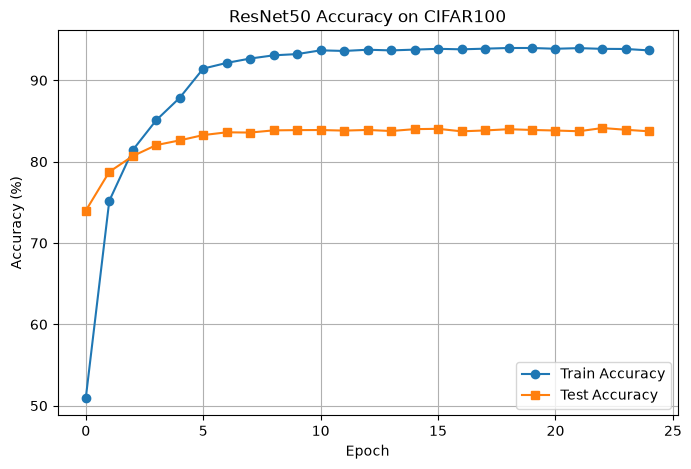

In [85]:
plt.figure(figsize=(8,5))

plt.plot(train_accs, marker='o', label='Train Accuracy')
plt.plot(test_accs, marker='s', label='Test Accuracy')

plt.title("ResNet50 Accuracy on CIFAR100")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.grid(True)
plt.legend()

plt.show()

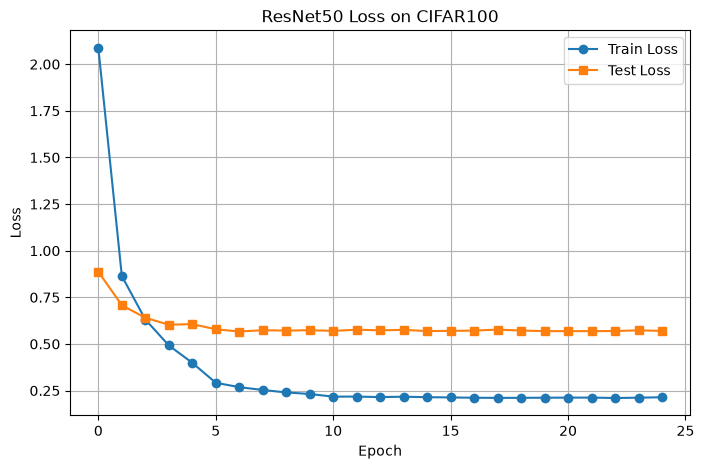

In [86]:
plt.figure(figsize=(8,5))

plt.plot(train_losses, marker='o', label='Train Loss')
plt.plot(test_losses, marker='s', label='Test Loss')

plt.title("ResNet50 Loss on CIFAR100")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.grid(True)
plt.legend()

plt.show()